In [1]:

# STEP 1: Import libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# STEP 2: Load COMPAS dataset

url = "https://raw.githubusercontent.com/propublica/compas-analysis/master/compas-scores-two-years.csv"

df = pd.read_csv(url)

# STEP 3: Display dataset information

print("Dataset loaded successfully!")

print("\nDataset Shape:")
print(df.shape)

print("\nFirst 5 Rows:")
display(df.head())

print("\nColumn Names:")
print(df.columns.tolist())

print("\nMissing Values:")
print(df.isnull().sum())


Dataset loaded successfully!

Dataset Shape:
(7214, 53)

First 5 Rows:


,id,name,first,last,compas_screening_date,sex,dob,age,age_cat,race,...,v_decile_score,v_score_text,v_screening_date,in_custody,out_custody,priors_count.1,start,end,event,two_year_recid
0,1,miguel hernandez,miguel,hernandez,2013-08-14,Male,1947-04-18,69,Greater than 45,Other,...,1,Low,2013-08-14,2014-07-07,2014-07-14,0,0,327,0,0
1,3,kevon dixon,kevon,dixon,2013-01-27,Male,1982-01-22,34,25 - 45,African-American,...,1,Low,2013-01-27,2013-01-26,2013-02-05,0,9,159,1,1
2,4,ed philo,ed,philo,2013-04-14,Male,1991-05-14,24,Less than 25,African-American,...,3,Low,2013-04-14,2013-06-16,2013-06-16,4,0,63,0,1
3,5,marcu brown,marcu,brown,2013-01-13,Male,1993-01-21,23,Less than 25,African-American,...,6,Medium,2013-01-13,NaN,NaN,1,0,1174,0,0
4,6,bouthy pierrelouis,bouthy,pierrelouis,2013-03-26,Male,1973-01-22,43,25 - 45,Other,...,1,Low,2013-03-26,NaN,NaN,2,0,1102,0,0



Column Names:
['id', 'name', 'first', 'last', 'compas_screening_date', 'sex', 'dob', 'age', 'age_cat', 'race', 'juv_fel_count', 'decile_score', 'juv_misd_count', 'juv_other_count', 'priors_count', 'days_b_screening_arrest', 'c_jail_in', 'c_jail_out', 'c_case_number', 'c_offense_date', 'c_arrest_date', 'c_days_from_compas', 'c_charge_degree', 'c_charge_desc', 'is_recid', 'r_case_number', 'r_charge_degree', 'r_days_from_arrest', 'r_offense_date', 'r_charge_desc', 'r_jail_in', 'r_jail_out', 'violent_recid', 'is_violent_recid', 'vr_case_number', 'vr_charge_degree', 'vr_offense_date', 'vr_charge_desc', 'type_of_assessment', 'decile_score.1', 'score_text', 'screening_date', 'v_type_of_assessment', 'v_decile_score', 'v_score_text', 'v_screening_date', 'in_custody', 'out_custody', 'priors_count.1', 'start', 'end', 'event', 'two_year_recid']

Missing Values:
id                            0
name                          0
first                         0
last                          0
compas_sc

In [2]:

# STEP 2: Understand the dataset

print("ALL COLUMNS:")
for col in df.columns:
    print(col)

print("\nDATA TYPES:")
print(df.dtypes)

print("\nMISSING VALUES (only columns with missing data):")
missing = df.isnull().sum()
print(missing[missing > 0].sort_values(ascending=False))

print("\nTARGET VARIABLE CHECK:")
print("Decile Score:")
print(df['decile_score'].value_counts().sort_index())

print("\nRecidivism:")
print(df['is_recid'].value_counts())


ALL COLUMNS:
id
name
first
last
compas_screening_date
sex
dob
age
age_cat
race
juv_fel_count
decile_score
juv_misd_count
juv_other_count
priors_count
days_b_screening_arrest
c_jail_in
c_jail_out
c_case_number
c_offense_date
c_arrest_date
c_days_from_compas
c_charge_degree
c_charge_desc
is_recid
r_case_number
r_charge_degree
r_days_from_arrest
r_offense_date
r_charge_desc
r_jail_in
r_jail_out
violent_recid
is_violent_recid
vr_case_number
vr_charge_degree
vr_offense_date
vr_charge_desc
type_of_assessment
decile_score.1
score_text
screening_date
v_type_of_assessment
v_decile_score
v_score_text
v_screening_date
in_custody
out_custody
priors_count.1
start
end
event
two_year_recid

DATA TYPES:
id                           int64
name                        object
first                       object
last                        object
compas_screening_date       object
sex                         object
dob                         object
age                          int64
age_cat                

In [3]:

# STEP 3: Select relevant columns

features = [
    'age',
    'sex',
    'race',
    'juv_fel_count',
    'juv_misd_count',
    'juv_other_count',
    'priors_count',
    'c_charge_degree'
]

targets = ['decile_score', 'is_recid']

# Create a separate dataset for our assignment
model_data = df[features + targets].copy()

# Remove rows only if target values are missing
model_data = model_data.dropna(subset=targets)

print("Selected Dataset Shape:")
print(model_data.shape)

print("\nMissing Values in Selected Features:")
print(model_data[features].isnull().sum())

print("\nDuplicate Rows:")
print(model_data.duplicated().sum())

print("\nFinal Dataset Preview:")
display(model_data.head())

print("\nTarget Variables:")
print(model_data[targets].describe())


Selected Dataset Shape:
(7214, 10)

Missing Values in Selected Features:
age                0
sex                0
race               0
juv_fel_count      0
juv_misd_count     0
juv_other_count    0
priors_count       0
c_charge_degree    0
dtype: int64

Duplicate Rows:
1088

Final Dataset Preview:


,age,sex,race,juv_fel_count,juv_misd_count,juv_other_count,priors_count,c_charge_degree,decile_score,is_recid
0,69,Male,Other,0,0,0,0,F,1,0
1,34,Male,African-American,0,0,0,0,F,3,1
2,24,Male,African-American,0,0,1,4,F,4,1
3,23,Male,African-American,0,1,0,1,F,8,0
4,43,Male,Other,0,0,0,2,F,1,0



Target Variables:
       decile_score     is_recid
count   7214.000000  7214.000000
mean       4.509565     0.481148
std        2.856396     0.499679
min        1.000000     0.000000
25%        2.000000     0.000000
50%        4.000000     0.000000
75%        7.000000     1.000000
max       10.000000     1.000000


In [4]:

# STEP 4: Train-Test Split

from sklearn.model_selection import train_test_split

# Separate input features
X = model_data[features]

# Separate target variables
y_linear = model_data['decile_score']
y_logistic = model_data['is_recid']

# Split the data: 70% training, 30% testing
X_train, X_test, y_linear_train, y_linear_test, y_logistic_train, y_logistic_test = train_test_split(
    X,
    y_linear,
    y_logistic,
    test_size=0.30,
    random_state=50
)

# Display the results
print("TRAINING AND TESTING SPLIT")
print("--------------------------------")
print("Total records:", len(model_data))
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nTraining percentage:", round(len(X_train)/len(model_data)*100, 2), "%")
print("Testing percentage:", round(len(X_test)/len(model_data)*100, 2), "%")

print("\nRecidivism distribution in training data:")
print(y_logistic_train.value_counts())

print("\nRecidivism distribution in testing data:")
print(y_logistic_test.value_counts())


TRAINING AND TESTING SPLIT
--------------------------------
Total records: 7214
Training records: 5049
Testing records: 2165

Training percentage: 69.99 %
Testing percentage: 30.01 %

Recidivism distribution in training data:
is_recid
0    2609
1    2440
Name: count, dtype: int64

Recidivism distribution in testing data:
is_recid
0    1134
1    1031
Name: count, dtype: int64


In [5]:

# STEP 5: Data Preprocessing

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

# Separate numerical and categorical columns
numeric_features = [
    'age',
    'juv_fel_count',
    'juv_misd_count',
    'juv_other_count',
    'priors_count'
]

categorical_features = [
    'sex',
    'race',
    'c_charge_degree'
]

# Create preprocessing transformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)

# Fit only on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Transform testing data
X_test_processed = preprocessor.transform(X_test)

# Display results
print("PREPROCESSING COMPLETED!")
print("--------------------------------")
print("Original training shape:", X_train.shape)
print("Processed training shape:", X_train_processed.shape)
print("Original testing shape:", X_test.shape)
print("Processed testing shape:", X_test_processed.shape)

print("\nNumerical features:", numeric_features)
print("Categorical features:", categorical_features)

print("\nMissing values in selected features:")
print(model_data[features].isnull().sum().sum())


PREPROCESSING COMPLETED!
--------------------------------
Original training shape: (5049, 8)
Processed training shape: (5049, 15)
Original testing shape: (2165, 8)
Processed testing shape: (2165, 15)

Numerical features: ['age', 'juv_fel_count', 'juv_misd_count', 'juv_other_count', 'priors_count']
Categorical features: ['sex', 'race', 'c_charge_degree']

Missing values in selected features:
0


In [6]:

# STEP 6: MODEL A - LINEAR REGRESSION

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Create Linear Regression model
linear_model = LinearRegression()

# Train the model
linear_model.fit(X_train_processed, y_linear_train)

# Make predictions
linear_predictions = linear_model.predict(X_test_processed)

# Evaluate the model
mse = mean_squared_error(y_linear_test, linear_predictions)
mae = mean_absolute_error(y_linear_test, linear_predictions)
r2 = r2_score(y_linear_test, linear_predictions)

print("LINEAR REGRESSION RESULTS")
print("--------------------------------")
print("Mean Squared Error:", round(mse, 4))
print("Mean Absolute Error:", round(mae, 4))
print("R2 Score:", round(r2, 4))

print("\nFirst 10 Actual vs Predicted Scores:")

comparison = pd.DataFrame({
    'Actual Score': y_linear_test.values[:10],
    'Predicted Score': linear_predictions[:10]
})

display(comparison)


LINEAR REGRESSION RESULTS
--------------------------------
Mean Squared Error: 4.7825
Mean Absolute Error: 1.7622
R2 Score: 0.4192

First 10 Actual vs Predicted Scores:


,Actual Score,Predicted Score
0,6,4.281526
1,3,5.360699
2,4,2.344516
3,3,3.608645
4,2,3.685930
5,4,4.213897
6,2,1.249507
7,1,2.662799
8,10,5.360699
9,6,3.731506


In [7]:

# STEP 7: MODEL B - LOGISTIC REGRESSION

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Create the model
logistic_model = LogisticRegression(max_iter=1000, random_state=50)

# Train the model
logistic_model.fit(X_train_processed, y_logistic_train)

# Predict probabilities
logistic_probabilities = logistic_model.predict_proba(X_test_processed)[:, 1]

# Predict final classes using 0.5 threshold
logistic_predictions = (logistic_probabilities >= 0.5).astype(int)

# Evaluate the model
accuracy = accuracy_score(y_logistic_test, logistic_predictions)
precision = precision_score(y_logistic_test, logistic_predictions)
recall = recall_score(y_logistic_test, logistic_predictions)
f1 = f1_score(y_logistic_test, logistic_predictions)

print("LOGISTIC REGRESSION RESULTS")
print("--------------------------------")
print("Accuracy:", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1 Score:", round(f1, 4))

print("\nCONFUSION MATRIX:")
print(confusion_matrix(y_logistic_test, logistic_predictions))

print("\nCLASSIFICATION REPORT:")
print(classification_report(y_logistic_test, logistic_predictions))


LOGISTIC REGRESSION RESULTS
--------------------------------
Accuracy: 0.6753
Precision: 0.6687
Recall: 0.6305
F1 Score: 0.649

CONFUSION MATRIX:
[[812 322]
 [381 650]]

CLASSIFICATION REPORT:
              precision    recall  f1-score   support

           0       0.68      0.72      0.70      1134
           1       0.67      0.63      0.65      1031

    accuracy                           0.68      2165
   macro avg       0.67      0.67      0.67      2165
weighted avg       0.67      0.68      0.67      2165



In [8]:

# STEP 8: MODEL COMPARISON

from sklearn.metrics import confusion_matrix

# Step 1: Calculate median of Linear Regression predictions
median_value = np.median(linear_predictions)

# Step 2: Classify Linear Regression predictions
linear_classes = (linear_predictions >= median_value).astype(int)

# Step 3: Classify Logistic Regression probabilities
logistic_classes = (logistic_probabilities >= 0.5).astype(int)

# Step 4: Compare both classifications
comparison_matrix = confusion_matrix(
    linear_classes,
    logistic_classes,
    labels=[0, 1]
)

# Step 5: Count mismatched predictions
mismatches = np.sum(linear_classes != logistic_classes)

total = len(linear_classes)
mismatch_percentage = (mismatches / total) * 100

print("MODEL COMPARISON RESULTS")
print("--------------------------------")

print("Median Linear Regression Prediction:", round(median_value, 4))

print("\nConfusion Matrix:")
print(comparison_matrix)

print("\nTotal Test Cases:", total)
print("Matching Predictions:", total - mismatches)
print("Mismatched Predictions:", mismatches)

print("Mismatch Percentage:", round(mismatch_percentage, 2), "%")


MODEL COMPARISON RESULTS
--------------------------------
Median Linear Regression Prediction: 4.5577

Confusion Matrix:
[[1030   52]
 [ 163  920]]

Total Test Cases: 2165
Matching Predictions: 1950
Mismatched Predictions: 215
Mismatch Percentage: 9.93 %


In [9]:

# STEP 9: SIMPSON'S PARADOX HUNT

import statsmodels.formula.api as smf
import pandas as pd
import numpy as np

# Define the full model formula
full_formula = (
    'is_recid ~ age + priors_count + juv_fel_count '
    '+ juv_misd_count + juv_other_count '
    '+ C(sex) + C(race) + C(c_charge_degree)'
)

# Subgroup formula (sex is excluded because each group has one sex)
subgroup_formula = (
    'is_recid ~ age + priors_count + juv_fel_count '
    '+ juv_misd_count + juv_other_count '
    '+ C(race) + C(c_charge_degree)'
)

# Fit model on full dataset
full_model = smf.logit(
    full_formula, data=model_data
).fit(disp=False, maxiter=200)

# Split into male and female groups
male_data = model_data[model_data['sex'] == 'Male'].copy()
female_data = model_data[model_data['sex'] == 'Female'].copy()

# Fit male subgroup model
male_model = smf.logit(
    subgroup_formula, data=male_data
).fit(disp=False, maxiter=200)

# Fit female subgroup model
female_model = smf.logit(
    subgroup_formula, data=female_data
).fit(disp=False, maxiter=200)

# Extract priors_count coefficient and statistics
results = []

for name, model in [
    ('Full Dataset', full_model),
    ('Male Subgroup', male_model),
    ('Female Subgroup', female_model)
]:
    results.append({
        'Model': name,
        'Sample Size': int(model.nobs),
        'Priors Coefficient': model.params['priors_count'],
        '95% CI Lower': model.conf_int().loc['priors_count', 0],
        '95% CI Upper': model.conf_int().loc['priors_count', 1],
        'P-value': model.pvalues['priors_count']
    })

simpson_results = pd.DataFrame(results)

print("SIMPSON'S PARADOX ANALYSIS")
print("--------------------------------")
display(simpson_results.round(4))

print("\nMale records:", len(male_data))
print("Female records:", len(female_data))


SIMPSON'S PARADOX ANALYSIS
--------------------------------


,Model,Sample Size,Priors Coefficient,95% CI Lower,95% CI Upper,P-value
0,Full Dataset,7214,0.1517,0.1372,0.1662,0.0
1,Male Subgroup,5819,0.1428,0.1275,0.1581,0.0
2,Female Subgroup,1395,0.2130,0.1685,0.2576,0.0



Male records: 5819
Female records: 1395


In [10]:

# STEP 9B: FORMAL INTERACTION TEST

interaction_formula = (
    'is_recid ~ age + priors_count * C(sex) '
    '+ juv_fel_count + juv_misd_count + juv_other_count '
    '+ C(race) + C(c_charge_degree)'
)

interaction_model = smf.logit(
    interaction_formula,
    data=model_data
).fit(disp=False, maxiter=200)

print("INTERACTION TEST RESULTS")
print("--------------------------------")

interaction_terms = [
    term for term in interaction_model.params.index
    if 'priors_count:C(sex)' in term
    or 'C(sex)[T.' in term and ':priors_count' in term
]

for term in interaction_terms:
    print("Interaction:", term)
    print("Coefficient:", round(interaction_model.params[term], 4))
    print("P-value:", interaction_model.pvalues[term])

print("\nFull interaction model summary:")
print(interaction_model.summary())


INTERACTION TEST RESULTS
--------------------------------
Interaction: priors_count:C(sex)[T.Male]
Coefficient: -0.0791
P-value: 0.0004991730020629117

Full interaction model summary:
                           Logit Regression Results                           
Dep. Variable:               is_recid   No. Observations:                 7214
Model:                          Logit   Df Residuals:                     7200
Method:                           MLE   Df Model:                           13
Date:                Sun, 22 Nov 2026   Pseudo R-squ.:                  0.1175
Time:                        00:44:38   Log-Likelihood:                -4408.4
converged:                       True   LL-Null:                       -4995.2
Covariance Type:            nonrobust   LLR p-value:                8.533e-243
                                  coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------

In [11]:

# PART 2.2: OMITTED VARIABLE BIAS

# Full model: includes all predictors
full_ovb_formula = (
    'is_recid ~ age + priors_count + juv_fel_count '
    '+ juv_misd_count + juv_other_count '
    '+ C(sex) + C(race) + C(c_charge_degree)'
)

# Reduced model: removes priors_count
reduced_ovb_formula = (
    'is_recid ~ age + juv_fel_count '
    '+ juv_misd_count + juv_other_count '
    '+ C(sex) + C(race) + C(c_charge_degree)'
)

# Fit both models
full_ovb_model = smf.logit(
    full_ovb_formula, data=model_data
).fit(disp=False, maxiter=200)

reduced_ovb_model = smf.logit(
    reduced_ovb_formula, data=model_data
).fit(disp=False, maxiter=200)

# Compare four predictors
predictors = [
    'age',
    'juv_fel_count',
    'juv_misd_count',
    'juv_other_count'
]

ovb_results = []

for predictor in predictors:

    before = full_ovb_model.params[predictor]
    after = reduced_ovb_model.params[predictor]

    percentage_change = (
        abs(after - before) / abs(before) * 100
        if before != 0 else np.nan
    )

    ovb_results.append({
        'Predictor': predictor,
        'Full Model': before,
        'Reduced Model': after,
        'Percentage Change': percentage_change
    })

ovb_table = pd.DataFrame(ovb_results)

print("OMITTED VARIABLE BIAS RESULTS")
print("--------------------------------")
display(ovb_table.round(4))

print("\nRemoved variable: priors_count")
print("Original coefficient:",
      round(full_ovb_model.params['priors_count'], 4))


OMITTED VARIABLE BIAS RESULTS
--------------------------------


,Predictor,Full Model,Reduced Model,Percentage Change
0,age,-0.0445,-0.0278,37.4858
1,juv_fel_count,0.1976,0.4887,147.3487
2,juv_misd_count,0.0486,0.3871,695.7123
3,juv_other_count,0.1953,0.2974,52.2836



Removed variable: priors_count
Original coefficient: 0.1517


In [12]:

# STEP 11: ADVERSARIAL SUBSET CONSTRUCTION

# Create a test results dataframe
test_results = X_test.copy()

test_results['Actual'] = y_logistic_test.values
test_results['Probability'] = logistic_probabilities
test_results['Predicted'] = logistic_predictions

# Identify confident but incorrect predictions
wrong_predictions = test_results[
    ((test_results['Probability'] >= 0.75) &
     (test_results['Actual'] == 0)) |
    ((test_results['Probability'] <= 0.25) &
     (test_results['Actual'] == 1))
].copy()

# Calculate total and percentage
wrong_count = len(wrong_predictions)
wrong_percentage = (wrong_count / len(test_results)) * 100

print("ADVERSARIAL SUBSET RESULTS")
print("--------------------------------")
print("Total test records:", len(test_results))
print("Confident wrong predictions:", wrong_count)
print("Percentage of test set:", round(wrong_percentage, 2), "%")

print("\nFalse Positives:")
print(len(wrong_predictions[
    (wrong_predictions['Probability'] >= 0.75) &
    (wrong_predictions['Actual'] == 0)
]))

print("\nFalse Negatives:")
print(len(wrong_predictions[
    (wrong_predictions['Probability'] <= 0.25) &
    (wrong_predictions['Actual'] == 1)
]))

# Select approximately 50 rows
if wrong_count > 50:
    adversarial_sample = wrong_predictions.sample(
        n=50, random_state=50
    )
else:
    adversarial_sample = wrong_predictions.copy()

print("\nSelected Adversarial Rows:", len(adversarial_sample))

# Compare demographics with full test set
demographic_columns = ['sex', 'race']

print("\nFULL TEST SET DEMOGRAPHICS")
for col in demographic_columns:
    print("\n", col)
    print((test_results[col].value_counts(normalize=True) * 100).round(2))

print("\nADVERSARIAL SUBSET DEMOGRAPHICS")
for col in demographic_columns:
    print("\n", col)
    print((adversarial_sample[col].value_counts(normalize=True) * 100).round(2))

# Compare age and previous offences
print("\nAGE COMPARISON")
print("Full test set mean age:",
      round(test_results['age'].mean(), 2))
print("Adversarial subset mean age:",
      round(adversarial_sample['age'].mean(), 2))

print("\nPRIOR OFFENCES COMPARISON")
print("Full test set mean priors:",
      round(test_results['priors_count'].mean(), 2))
print("Adversarial subset mean priors:",
      round(adversarial_sample['priors_count'].mean(), 2))

print("\nPercentage with 5 or more prior offences:")
print("Full test set:",
      round((test_results['priors_count'] >= 5).mean() * 100, 2), "%")
print("Adversarial subset:",
      round((adversarial_sample['priors_count'] >= 5).mean() * 100, 2), "%")

# Display selected rows
print("\nSAMPLE OF ADVERSARIAL CASES")
display(adversarial_sample.head(10))


ADVERSARIAL SUBSET RESULTS
--------------------------------
Total test records: 2165
Confident wrong predictions: 102
Percentage of test set: 4.71 %

False Positives:
35

False Negatives:
67

Selected Adversarial Rows: 50

FULL TEST SET DEMOGRAPHICS

 sex
sex
Male      79.77
Female    20.23
Name: proportion, dtype: float64

 race
race
African-American    50.81
Caucasian           34.87
Hispanic             9.05
Other                4.80
Native American      0.32
Asian                0.14
Name: proportion, dtype: float64

ADVERSARIAL SUBSET DEMOGRAPHICS

 sex
sex
Male      66.0
Female    34.0
Name: proportion, dtype: float64

 race
race
African-American    48.0
Caucasian           42.0
Hispanic            10.0
Name: proportion, dtype: float64

AGE COMPARISON
Full test set mean age: 34.87
Adversarial subset mean age: 45.74

PRIOR OFFENCES COMPARISON
Full test set mean priors: 3.59
Adversarial subset mean priors: 6.78

Percentage with 5 or more prior offences:
Full test set: 25.22 %
Adver

,age,sex,race,juv_fel_count,juv_misd_count,juv_other_count,priors_count,c_charge_degree,Actual,Probability,Predicted
2745,44,Female,Caucasian,0,0,0,1,F,1,0.229610,0
375,50,Female,Caucasian,0,0,0,1,M,1,0.171698,0
6943,34,Male,Caucasian,0,0,0,11,F,0,0.765969,1
7096,65,Male,Hispanic,0,0,0,2,M,1,0.123546,0
5325,37,Male,African-American,3,0,0,12,M,0,0.869751,1
576,49,Female,Caucasian,0,0,0,2,M,1,0.201913,0
3493,34,Male,African-American,0,1,0,27,M,0,0.976322,1
428,48,Male,Hispanic,0,0,0,1,M,1,0.209047,0
2310,49,Male,Hispanic,0,0,0,1,F,1,0.215938,0
502,52,Male,Hispanic,0,0,0,20,F,0,0.815274,1


FAIRNESS METRICS AT DIFFERENT THRESHOLDS
--------------------------------


,Threshold,Demographic Parity,Equalized Odds,Predictive Parity
0,0.05,1.0000,1.0000,1.2154
1,0.15,1.0633,1.0324,1.1800
2,0.25,1.1780,1.1598,1.1966
3,0.35,1.4796,1.3034,1.0706
4,0.45,2.2511,1.7737,0.9576
5,0.55,3.0612,2.4594,0.9764
6,0.65,3.1195,2.1121,1.2114
7,0.75,3.3647,1.7849,1.2739
8,0.85,5.3767,3.7979,0.8585
9,0.95,NaN,NaN,NaN


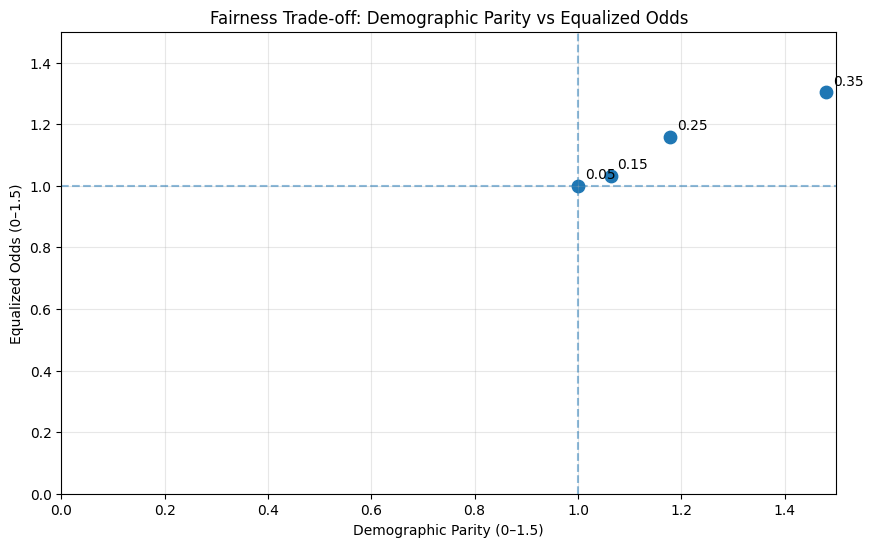

In [13]:

# STEP 12: FAIRNESS TRADE-OFF ANALYSIS

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Use gender as the sensitive variable
gender = X_test['sex'].reset_index(drop=True)
actual = np.array(y_logistic_test)
probabilities = logistic_probabilities

# Define groups
group_A = 'Male'
group_B = 'Female'

# Thresholds from 0.05 to 0.95
thresholds = np.arange(0.05, 1.00, 0.10)

def safe_ratio(a, b):
    if b == 0 or np.isnan(b):
        return np.nan
    return a / b

fairness_results = []

for threshold in thresholds:

    # Predictions at current threshold
    predicted = (probabilities >= threshold).astype(int)

    # Separate groups
    mask_A = (gender == group_A).to_numpy()
    mask_B = (gender == group_B).to_numpy()

    y_A = actual[mask_A]
    y_B = actual[mask_B]

    p_A = predicted[mask_A]
    p_B = predicted[mask_B]

    # Demographic Parity
    selection_A = p_A.mean()
    selection_B = p_B.mean()

    DP = safe_ratio(selection_A, selection_B)

    # True Positive Rates
    TPR_A = ((p_A == 1) & (y_A == 1)).sum() / max((y_A == 1).sum(), 1)
    TPR_B = ((p_B == 1) & (y_B == 1)).sum() / max((y_B == 1).sum(), 1)

    # False Positive Rates
    FPR_A = ((p_A == 1) & (y_A == 0)).sum() / max((y_A == 0).sum(), 1)
    FPR_B = ((p_B == 1) & (y_B == 0)).sum() / max((y_B == 0).sum(), 1)

    EO = min(
        safe_ratio(TPR_A, TPR_B),
        safe_ratio(FPR_A, FPR_B)
    )

    # Predictive Parity
    PP_A = ((p_A == 1) & (y_A == 1)).sum() / max((p_A == 1).sum(), 1)
    PP_B = ((p_B == 1) & (y_B == 1)).sum() / max((p_B == 1).sum(), 1)

    PP = safe_ratio(PP_A, PP_B)

    fairness_results.append({
        'Threshold': round(threshold, 2),
        'Demographic Parity': DP,
        'Equalized Odds': EO,
        'Predictive Parity': PP
    })

# Create fairness table
fairness_df = pd.DataFrame(fairness_results)

print("FAIRNESS METRICS AT DIFFERENT THRESHOLDS")
print("--------------------------------")
display(fairness_df.round(4))

# Create trade-off chart
plt.figure(figsize=(10, 6))

plt.scatter(
    fairness_df['Demographic Parity'],
    fairness_df['Equalized Odds'],
    s=80
)

for _, row in fairness_df.iterrows():
    if pd.notna(row['Demographic Parity']) and pd.notna(row['Equalized Odds']):
        plt.annotate(
            f"{row['Threshold']:.2f}",
            (row['Demographic Parity'], row['Equalized Odds']),
            xytext=(5, 5),
            textcoords='offset points'
        )

plt.axvline(1, linestyle='--', alpha=0.5)
plt.axhline(1, linestyle='--', alpha=0.5)

plt.xlim(0, 1.5)
plt.ylim(0, 1.5)

plt.xlabel("Demographic Parity (0–1.5)")
plt.ylabel("Equalized Odds (0–1.5)")
plt.title("Fairness Trade-off: Demographic Parity vs Equalized Odds")
plt.grid(alpha=0.3)
plt.show()


In [14]:

# STEP 13: THRESHOLD PERFORMANCE COMPARISON

from sklearn.metrics import accuracy_score, precision_score, recall_score

selected_thresholds = [0.05, 0.15, 0.35, 0.45, 0.85]

threshold_comparison = []

for t in selected_thresholds:

    predictions = (logistic_probabilities >= t).astype(int)

    threshold_comparison.append({
        'Threshold': t,
        'Accuracy': accuracy_score(y_logistic_test, predictions),
        'Precision': precision_score(
            y_logistic_test, predictions, zero_division=0
        ),
        'Recall': recall_score(
            y_logistic_test, predictions, zero_division=0
        )
    })

threshold_performance = pd.DataFrame(threshold_comparison)

print("THRESHOLD PERFORMANCE COMPARISON")
display(threshold_performance.round(4))

print("\nFAIRNESS RESULTS AT SELECTED THRESHOLDS")
display(
    fairness_df[
        fairness_df['Threshold'].isin(selected_thresholds)
    ].round(4)
)


THRESHOLD PERFORMANCE COMPARISON


,Threshold,Accuracy,Precision,Recall
0,0.05,0.4762,0.4762,1.0000
1,0.15,0.4919,0.4836,0.9864
2,0.35,0.5986,0.5504,0.8574
3,0.45,0.6564,0.6201,0.7187
4,0.85,0.5612,0.8649,0.0931



FAIRNESS RESULTS AT SELECTED THRESHOLDS


,Threshold,Demographic Parity,Equalized Odds,Predictive Parity
0,0.05,1.0000,1.0000,1.2154
1,0.15,1.0633,1.0324,1.1800
3,0.35,1.4796,1.3034,1.0706
4,0.45,2.2511,1.7737,0.9576
8,0.85,5.3767,3.7979,0.8585


In [15]:

# FINAL DATA PREPROCESSING CHECK: OUTLIER ANALYSIS

outlier_columns = [
    'age',
    'juv_fel_count',
    'juv_misd_count',
    'juv_other_count',
    'priors_count'
]

outlier_results = []

for col in outlier_columns:

    Q1 = model_data[col].quantile(0.25)
    Q3 = model_data[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    count = (
        (model_data[col] < lower) |
        (model_data[col] > upper)
    ).sum()

    outlier_results.append({
        'Feature': col,
        'Lower Bound': lower,
        'Upper Bound': upper,
        'Outlier Count': count,
        'Outlier Percentage': count / len(model_data) * 100
    })

outlier_table = pd.DataFrame(outlier_results)

print("OUTLIER ANALYSIS USING IQR METHOD")
display(outlier_table.round(2))

print("\nNOTE:")
print("Outliers are investigated, not automatically deleted.")
print("Criminal history counts may represent legitimate observations.")


OUTLIER ANALYSIS USING IQR METHOD


,Feature,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage
0,age,-0.5,67.5,61,0.85
1,juv_fel_count,0.0,0.0,282,3.91
2,juv_misd_count,0.0,0.0,415,5.75
3,juv_other_count,0.0,0.0,523,7.25
4,priors_count,-7.5,12.5,455,6.31



NOTE:
Outliers are investigated, not automatically deleted.
Criminal history counts may represent legitimate observations.


In [16]:

# FINAL VERIFICATION: DATASET AND MODEL RESULTS

print("FINAL ASSIGNMENT VERIFICATION")
print("--------------------------------")

print("Dataset records:", len(model_data))
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nMODEL RESULTS")
print("Linear Regression R2:", round(r2, 4))
print("Logistic Regression Accuracy:", round(accuracy, 4))

print("\nMODEL COMPARISON")
print("Median threshold:", round(median_value, 4))
print("Mismatches:", mismatches)
print("Mismatch percentage:", round(mismatch_percentage, 2), "%")

print("\nSIMpson's PARADOX")
display(simpson_results.round(4))

print("\nOMITTED VARIABLE BIAS")
display(ovb_table.round(4))

print("\nADVERSARIAL ANALYSIS")
print("Confident errors:", wrong_count)
print("Error percentage:", round(wrong_percentage, 2), "%")

print("\nFAIRNESS ANALYSIS")
display(fairness_df.round(4))


FINAL ASSIGNMENT VERIFICATION
--------------------------------
Dataset records: 7214
Training records: 5049
Testing records: 2165

MODEL RESULTS
Linear Regression R2: 0.4192
Logistic Regression Accuracy: 0.6753

MODEL COMPARISON
Median threshold: 4.5577
Mismatches: 215
Mismatch percentage: 9.93 %

SIMpson's PARADOX


,Model,Sample Size,Priors Coefficient,95% CI Lower,95% CI Upper,P-value
0,Full Dataset,7214,0.1517,0.1372,0.1662,0.0
1,Male Subgroup,5819,0.1428,0.1275,0.1581,0.0
2,Female Subgroup,1395,0.2130,0.1685,0.2576,0.0



OMITTED VARIABLE BIAS


,Predictor,Full Model,Reduced Model,Percentage Change
0,age,-0.0445,-0.0278,37.4858
1,juv_fel_count,0.1976,0.4887,147.3487
2,juv_misd_count,0.0486,0.3871,695.7123
3,juv_other_count,0.1953,0.2974,52.2836



ADVERSARIAL ANALYSIS
Confident errors: 102
Error percentage: 4.71 %

FAIRNESS ANALYSIS


,Threshold,Demographic Parity,Equalized Odds,Predictive Parity
0,0.05,1.0000,1.0000,1.2154
1,0.15,1.0633,1.0324,1.1800
2,0.25,1.1780,1.1598,1.1966
3,0.35,1.4796,1.3034,1.0706
4,0.45,2.2511,1.7737,0.9576
5,0.55,3.0612,2.4594,0.9764
6,0.65,3.1195,2.1121,1.2114
7,0.75,3.3647,1.7849,1.2739
8,0.85,5.3767,3.7979,0.8585
9,0.95,NaN,NaN,NaN
